# 1.3 Construcción de etiquetas

Actividad **1.3**: generar la etiqueta binaria y la multiclase para *H* = 24 h, y reportar la proporción de positivos por conjunto y por componente.

## Definición

Para cada máquina *m* y hora *t*:

| etiqueta | definición |
|---|---|
| **binaria** `y_bin` | 1 si hay una falla de cualquier componente en (*t*, *t* + 24 h]; 0 si no. |
| **multiclase** `y_cls` | 0 = ninguno, 1–4 = comp1–comp4, el componente que fallará en (*t*, *t* + 24 h]. |

Decisiones:

- **Intervalo abierto a la izquierda.** La hora de la falla no es positiva para sí misma, porque en esa hora el registro de reparación ya existe (1.2).
- **Solo desde `PdM_failures`**, nunca desde `PdM_maint`.
- **Varios componentes en la ventana.** Se toma el de la falla más próxima; si fallan a la misma hora, el componente menos frecuente en entrenamiento.
- **Margen de *H* horas en cada frontera.** *t* pertenece a un conjunto solo si *t* + 24 h también cae en él.

Código: `src/labels.py`.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_telemetry, load_failures, SPLITS, COMPS, H
from src.labels import make_labels, assign_label_split, CLASSES, TIE_PRIORITY
from src.plots import set_style, savefig

set_style()
pd.set_option("display.precision", 4)
COMP_COLORS = dict(zip(COMPS, sns.color_palette("deep", 4)))
SPLIT_ORDER = ["train", "val", "test"]

tel = load_telemetry()
fail = load_failures()

# Orden de desempate: de menos a más fallas en train
lo, hi = SPLITS["train"]
train_counts = fail[(fail["datetime"] >= lo) & (fail["datetime"] <= hi)]["failure"].value_counts()
assert list(train_counts.sort_values(kind="stable").index) == TIE_PRIORITY
train_counts

failure
comp2    168
comp1    141
comp4    122
comp3     91
Name: count, dtype: int64

In [2]:
labels = make_labels(tel, fail, h=H)
labels["split"] = assign_label_split(labels["datetime"], h=H).values

# Verificaciones
assert ((labels["y_cls"] > 0) == (labels["y_bin"] == 1)).all()
assert ((labels["h_to_failure"] <= H) == (labels["y_bin"] == 1)).all()
for s, (lo, hi) in SPLITS.items():
    t = labels.loc[labels["split"] == s, "datetime"]
    assert (t + pd.Timedelta(hours=H)).max() <= hi and t.min() >= lo
labels.groupby("split")["datetime"].agg(["min", "max"]).loc[SPLIT_ORDER]

,min,max
split,,
train,2015-01-01 06:00:00,2015-08-30 23:00:00
val,2015-09-01 00:00:00,2015-10-30 23:00:00
test,2015-11-01 00:00:00,2015-12-30 23:00:00


## Proporción de positivos por conjunto

In [3]:
lab = labels.assign(conjunto=labels["split"].fillna("margen (excluido)"))
by_split = lab.groupby("conjunto").agg(horas=("y_bin", "size"), horas_positivas=("y_bin", "sum"),
                                       tasa_positivos=("y_bin", "mean"))
by_split["razón neg:pos"] = (by_split["horas"] - by_split["horas_positivas"]) / by_split["horas_positivas"]
by_split = by_split.loc[SPLIT_ORDER + ["margen (excluido)"]]
by_split.style.format({"tasa_positivos": "{:.3%}", "razón neg:pos": "{:.1f} : 1"})

,horas,horas_positivas,tasa_positivos,razón neg:pos
conjunto,,,,
train,580200,11742,2.024%,48.4 : 1
val,144000,2652,1.842%,53.3 : 1
test,144000,2658,1.846%,53.2 : 1
margen (excluido),7900,132,1.671%,58.8 : 1


## Proporción por componente

In [4]:
used = labels[labels["split"].notna()].assign(clase=lambda x: pd.Categorical.from_codes(x["y_cls"], CLASSES))
mc_counts = pd.crosstab(used["split"], used["clase"]).loc[SPLIT_ORDER, CLASSES]
mc_rate = mc_counts.div(mc_counts.sum(axis=1), axis=0)
mc_share = mc_counts[COMPS].div(mc_counts[COMPS].sum(axis=1), axis=0)
print("Horas por clase"); display(mc_counts)
print("Tasa por clase (sobre todas las horas del conjunto)"); display(mc_rate.style.format("{:.3%}"))
print("Reparto de las horas positivas entre componentes"); display(mc_share.style.format("{:.1%}"))

Horas por clase


clase,ninguno,comp1,comp2,comp3,comp4
split,,,,,
train,568458,3192,3561,2142,2847
val,141348,456,1026,474,696
test,141342,654,960,444,600


Tasa por clase (sobre todas las horas del conjunto)


clase,ninguno,comp1,comp2,comp3,comp4
split,,,,,
train,97.976%,0.550%,0.614%,0.369%,0.491%
val,98.158%,0.317%,0.713%,0.329%,0.483%
test,98.154%,0.454%,0.667%,0.308%,0.417%


Reparto de las horas positivas entre componentes


clase,comp1,comp2,comp3,comp4
split,,,,
train,27.2%,30.3%,18.2%,24.2%
val,17.2%,38.7%,17.9%,26.2%
test,24.6%,36.1%,16.7%,22.6%


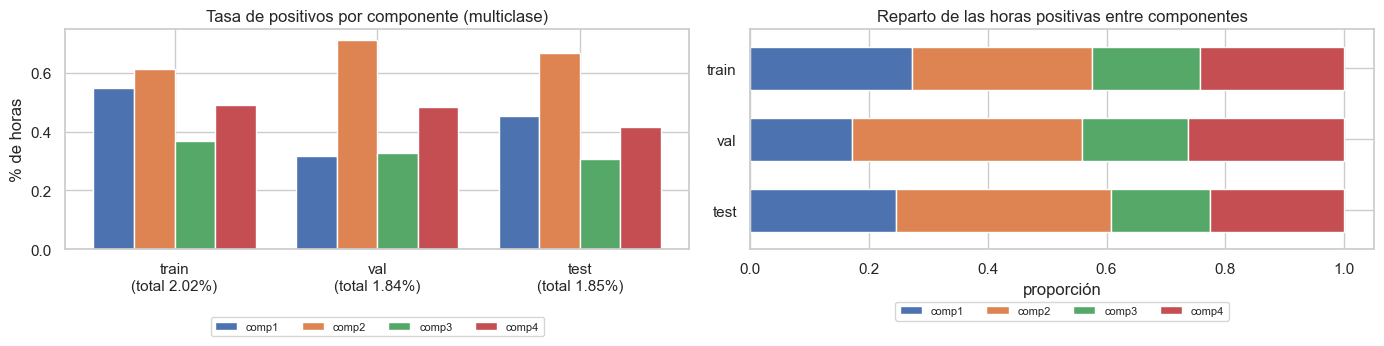

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(len(SPLIT_ORDER))
w = 0.2
for i, c in enumerate(COMPS):
    axes[0].bar(x + (i - 1.5) * w, mc_rate.loc[SPLIT_ORDER, c] * 100, w, color=COMP_COLORS[c], label=c)
axes[0].set(xticks=x, xticklabels=[f"{s}\n(total {by_split.loc[s, 'tasa_positivos']:.2%})" for s in SPLIT_ORDER],
            ylabel="% de horas", title="Tasa de positivos por componente (multiclase)")
axes[0].legend(ncol=4, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.42))
mc_share.loc[SPLIT_ORDER].plot.barh(stacked=True, ax=axes[1], color=[COMP_COLORS[c] for c in COMPS], width=0.6)
axes[1].set(title="Reparto de las horas positivas entre componentes", xlabel="proporción", ylabel="")
axes[1].invert_yaxis()
axes[1].legend(ncol=4, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.35))
plt.tight_layout()
savefig(fig, "05_label_balance")

## Resumen

- **Desbalance:** ≈ 2 % de horas positivas en los tres conjuntos (≈ 50 negativas por positiva). Cada componente queda entre 0.3 % y 0.7 % de las horas.
- **Reparto entre componentes:** comp2 es la clase más frecuente en los tres conjuntos. En validación comp1 baja al 17 % de los positivos (27 % en train).
- **Margen:** se excluyen las últimas 24 h de cada conjunto, de modo que ninguna etiqueta cruza una frontera.